# 7. Multi-instrument joint analysis

## Aim
The aim of this tutorial is to do a joint spectral analysis using H.E.S.S. and Fermi-LAT data of AGN PKS 2155-305.

In [1]:
from gammapy.data import DataStore, EventList
from gammapy.irf import PSFMap, EDispKernelMap
from gammapy.maps import MapAxis, RegionGeom, WcsGeom, Map
from gammapy.makers import SpectrumDatasetMaker, SafeMaskMaker, ReflectedRegionsBackgroundMaker
from gammapy.datasets import SpectrumDataset, Datasets, FluxPointsDataset, MapDataset
from gammapy.catalog import CATALOG_REGISTRY, SourceCatalog4FGL
from gammapy.modeling.models import (
    Models,
    PowerLawSpectralModel,
    SkyModel,
    EBLAbsorptionNormSpectralModel, 
    ExpCutoffPowerLawSpectralModel,
    create_fermi_isotropic_diffuse_model,
    TemplateSpatialModel,
    PowerLawNormSpectralModel
)
from gammapy.modeling import Fit
from gammapy.estimators import FluxPointsEstimator

from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.time import Time
from regions import CircleSkyRegion

import matplotlib.pyplot as plt

## H.E.S.S.

Select H.E.S.S. observations for PKS 2155-304 that you can find in the Gammapy datasets in `$GAMMAPY_DATA`

In [2]:
data_store = DataStore.from_dir("$GAMMAPY_DATA/hess-dl3-dr1/")

In [3]:
target_pos = SkyCoord.from_name("PKS 2155-304")

In [4]:
obs_time = Time(["2008-08-26", "2008-09-06"], scale="tt")

In [5]:
obs_table = data_store.obs_table
obs_table = obs_table.select_sky_circle(target_pos, 2.5*u.deg)
obs_table = obs_table.select_time_range(obs_time)

Display the content of the `obs_table`

In [6]:
obs_table

OBS_ID,RA_PNT,DEC_PNT,GLON_PNT,GLAT_PNT,ZEN_PNT,ALT_PNT,AZ_PNT,OBJECT,RA_OBJ,DEC_OBJ,OFFSET_OBJ,ONTIME,LIVETIME,DEADC,TSTART,TSTOP,DATE-OBS,TIME-OBS,DATE-END,TIME-END,N_TELS,TELLIST,QUALITY,MUONEFF,EVENT_COUNT,TARGET_NAME,TARGET_TAG,TARGET_OFFSET,SAFE_ENERGY_LO,SAFE_ENERGY_HI
,deg,deg,deg,deg,deg,deg,deg,,deg,deg,deg,s,s,,s,s,,,,,,,,,,,,deg,TeV,TeV
int64,float32,float32,float32,float32,float32,float32,float32,bytes18,float32,float32,float32,float32,float32,float32,float64,float64,bytes10,bytes12,bytes10,bytes12,int64,bytes7,int64,float32,int64,bytes21,bytes14,float32,float32,float32
47802,330.29538,-30.225555,17.818897,-52.742733,36.828686,53.171314,110.0,PKS 2155-304,329.71667,-30.225555,0.50002956,1688.0,1572.4065,0.9315204,241558291.0,241559979.0,2008-08-27,19:32:35.184,2008-08-27,20:00:43.184,4,"1,2,3,4",0,0.9731573,5998,PKS 2155-304 (steady),pks2155_steady,0.4998021,0.61659503,100.0
47803,329.13797,-30.225555,17.639944,-51.748703,30.231466,59.768536,110.04136,PKS 2155-304,329.71667,-30.225555,0.50002956,1688.0,1566.9369,0.9282802,241560121.0,241561809.0,2008-08-27,20:03:05.184,2008-08-27,20:31:13.184,4,"1,2,3,4",0,0.9795774,6243,PKS 2155-304 (steady),pks2155_steady,0.5002569,0.43651584,100.0
47804,329.71667,-29.725555,18.541153,-52.188046,23.713928,66.28607,112.64086,PKS 2155-304,329.71667,-30.225555,0.5,1689.0,1560.2717,0.9237843,241561944.0,241563633.0,2008-08-27,20:33:28.184,2008-08-27,21:01:37.184,4,"1,2,3,4",0,0.9836817,6445,PKS 2155-304 (steady),pks2155_steady,0.500033,0.40738028,100.0
47827,330.29538,-30.225555,17.818897,-52.742733,35.87235,54.12765,110.0,PKS 2155-304,329.71667,-30.225555,0.50002956,1688.0,1575.5515,0.9333836,241644720.0,241646408.0,2008-08-28,19:33:04.184,2008-08-28,20:01:12.184,4,"1,2,3,4",0,0.9898478,5703,PKS 2155-304 (steady),pks2155_steady,0.4998021,0.61659503,100.0
47828,329.13797,-30.225555,17.639944,-51.748703,29.29926,60.70074,110.1458,PKS 2155-304,329.71667,-30.225555,0.50002956,1687.0,1562.4288,0.9261582,241646545.0,241648232.0,2008-08-28,20:03:29.184,2008-08-28,20:31:36.184,4,"1,2,3,4",0,0.9777505,6030,PKS 2155-304 (steady),pks2155_steady,0.5002569,0.43651584,100.0
47829,329.71667,-30.725555,16.917807,-52.297615,22.831352,67.16865,113.11527,PKS 2155-304,329.71667,-30.225555,0.5,1688.0,1559.6072,0.9239379,241648358.0,241650046.0,2008-08-28,20:33:42.184,2008-08-28,21:01:50.184,4,"1,2,3,4",0,0.96896285,6469,PKS 2155-304 (steady),pks2155_steady,0.49996707,0.3801894,100.0


In [7]:
len(obs_table)

6

Get the observations

In [8]:
observations = data_store.get_observations(obs_table["OBS_ID"])

In [9]:
print(observations)

Observations
Number of observations: 6
Observation

	obs id            : 47802 
 	tstart            : 54705.81
	tstop             : 54705.83
	duration          : 1688.00 s
	pointing (icrs)   : 330.3 deg, -30.2 deg

	deadtime fraction : 6.8%
Observation

	obs id            : 47803 
 	tstart            : 54705.84
	tstop             : 54705.86
	duration          : 1688.00 s
	pointing (icrs)   : 329.1 deg, -30.2 deg

	deadtime fraction : 7.2%
Observation

	obs id            : 47804 
 	tstart            : 54705.86
	tstop             : 54705.88
	duration          : 1689.00 s
	pointing (icrs)   : 329.7 deg, -29.7 deg

	deadtime fraction : 7.6%
Observation

	obs id            : 47827 
 	tstart            : 54706.81
	tstop             : 54706.83
	duration          : 1688.00 s
	pointing (icrs)   : 330.3 deg, -30.2 deg

	deadtime fraction : 6.7%
Observation

	obs id            : 47828 
 	tstart            : 54706.84
	tstop             : 54706.86
	duration          : 1687.00 s
	pointing (icrs)   :

### Data reduction to DL4

In [10]:
on_region = CircleSkyRegion(target_pos, 0.1 * u.deg)

In [11]:
energy_axis = MapAxis.from_energy_bounds(
    0.1, 40, nbin=10, per_decade=True, unit="TeV", name="energy"
)
energy_axis_true = MapAxis.from_energy_bounds(
    0.05, 100, nbin=20, per_decade=True, unit="TeV", name="energy_true"
)

geom = RegionGeom.create(region=on_region, axes=[energy_axis])
dataset_empty = SpectrumDataset.create(geom=geom, energy_axis_true=energy_axis_true)

dataset_maker = SpectrumDatasetMaker(
    containment_correction=True, selection=["counts", "exposure", "edisp"]
)
bkg_maker = ReflectedRegionsBackgroundMaker()
safe_mask_masker = SafeMaskMaker(methods=["aeff-max"], aeff_percent=10)

In [12]:
obs_ids = observations.ids
datasets = Datasets()

for obs_id, observation in zip(obs_ids, observations):
    dataset = dataset_maker.run(dataset_empty.copy(name=str(obs_id)), observation)
    dataset_on_off = bkg_maker.run(dataset, observation)
    dataset_on_off = safe_mask_masker.run(dataset_on_off, observation)
    datasets.append(dataset_on_off)

print(datasets)

Datasets
--------

Dataset 0: 

  Type       : SpectrumDatasetOnOff
  Name       : 47802
  Instrument : HESS
  Models     : 

Dataset 1: 

  Type       : SpectrumDatasetOnOff
  Name       : 47803
  Instrument : HESS
  Models     : 

Dataset 2: 

  Type       : SpectrumDatasetOnOff
  Name       : 47804
  Instrument : HESS
  Models     : 

Dataset 3: 

  Type       : SpectrumDatasetOnOff
  Name       : 47827
  Instrument : HESS
  Models     : 

Dataset 4: 

  Type       : SpectrumDatasetOnOff
  Name       : 47828
  Instrument : HESS
  Models     : 

Dataset 5: 

  Type       : SpectrumDatasetOnOff
  Name       : 47829
  Instrument : HESS
  Models     : 




Stack the dataset using `stack_reduce`

In [13]:
hess_dataset = datasets.stack_reduce()

## Fermi-LAT

This is a simplified version. For more details on real Fermi-LAT analysis with Gammapy see https://docs.gammapy.org/2.0/tutorials/data/fermi_lat.html

Besides the files already provided in the repository, you need to download Galactic interstellar emission model `gll_iem_v07.fits` from https://fermi.gsfc.nasa.gov/ssc/data/access/lat/BackgroundModels.html as they are large files.

Read the events using `EventList.read`. Fermi-LAT events are stored in the file "ft1_00.fits"

In [14]:
events = EventList.read("ft1_00.fits")

In [15]:
print(events)

EventList
---------

  Instrument       : LAT
  Telescope        : GLAST
  Obs. ID          : 

  Number of events : 630
  Event rate       : 0.001 1 / s

  Time start       : 54704.000754444445
  Time stop        : 54715.000754444445

  Min. energy      : 2.00e+02 MeV
  Max. energy      : 4.19e+04 MeV
  Median energy    : 4.10e+02 MeV




In [16]:
events.table

TIME,ENERGY,RA,DEC,L,B,THETA,PHI,ZENITH_ANGLE,EARTH_AZIMUTH_ANGLE,EVENT_ID,RUN_ID,RECON_VERSION,CALIB_VERSION,EVENT_CLASS,EVENT_TYPE,CONVERSION_TYPE,LIVETIME,DIFRSP0,DIFRSP1,DIFRSP2,DIFRSP3,DIFRSP4
,MeV,deg,deg,deg,deg,deg,deg,deg,deg,,,,,,,,s,,,,,
Time,float32,float32,float32,float32,float32,float32,float32,float32,float32,int32,int32,int16,int16[3],bool[32],bool[32],int16,float64,float32,float32,float32,float32,float32
54710.78128322223,858.8792,333.12192,-23.725653,29.30648,-54.097145,32.316307,165.16573,28.091183,142.64781,6892216,241984516,0,0 .. 0,False .. True,False .. True,0,53.597787618637085,0.0,0.0,0.0,0.0,0.0
54704.94557826125,207.45532,335.7745,-25.522879,27.13889,-56.842373,6.618401,178.26152,29.350693,211.9563,7326845,241480337,0,0 .. 0,False .. True,False .. True,0,136.37941387295723,0.0,0.0,0.0,0.0,0.0
54705.946654891944,1338.4224,335.38297,-25.015612,27.913506,-56.393997,68.472374,193.81874,40.977856,249.03566,8659744,241566277,0,0 .. 0,False .. True,False .. False,1,156.76379770040512,0.0,0.0,0.0,0.0,0.0
54706.817505859304,423.0177,336.52,-26.02873,26.450539,-57.595818,63.952934,190.00992,75.32312,247.80884,9617589,241640759,0,0 .. 0,False .. True,False .. True,0,18.317135006189346,0.0,0.0,0.0,0.0,0.0
54707.195243356226,441.5131,334.59448,-24.430859,28.658962,-55.56878,32.967598,155.95055,40.474422,149.15858,9754410,241673636,0,0 .. 0,False .. True,False .. True,0,176.95219510793686,0.0,0.0,0.0,0.0,0.0
54708.53400289108,328.32962,336.67642,-27.343445,24.058662,-57.943592,24.567049,193.25214,29.658623,244.95168,6547029,241789698,0,0 .. 0,False .. True,False .. False,1,80.41369599103928,0.0,0.0,0.0,0.0,0.0
54709.731165228724,274.10733,337.91675,-28.455286,22.201437,-59.16808,34.297943,194.11908,37.097027,252.28847,8128655,241892847,0,0 .. 0,False .. True,False .. True,0,74.81019324064255,0.0,0.0,0.0,0.0,0.0
54711.58677269955,249.80746,336.89337,-27.177269,24.421429,-58.110657,28.124403,191.43874,21.876955,249.79276,6861554,242053458,0,0 .. 0,False .. True,False .. True,0,31.341847330331802,0.0,0.0,0.0,0.0,0.0


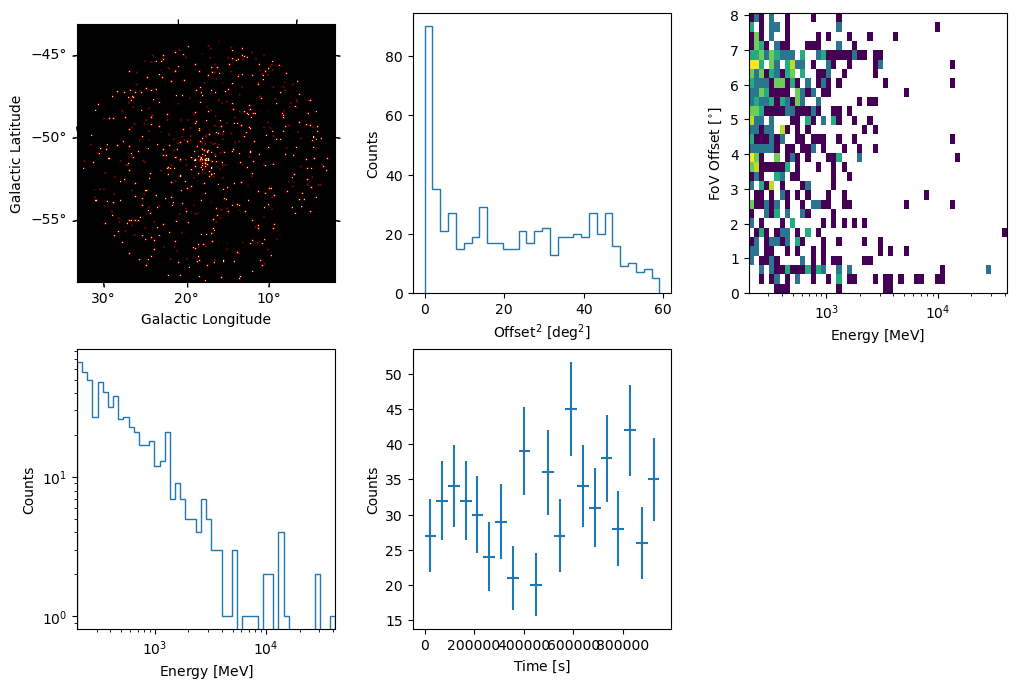

In [17]:
events.peek()

create an energy axis from 0.2 to 300 GeV with 8 bins

In [18]:
energy_axis = MapAxis.from_energy_bounds(0.2, 300.0, 8,per_decade=True, unit="GeV")
print(energy_axis)

MapAxis

	name       : energy    
	unit       : 'GeV'     
	nbins      : 26        
	node type  : edges     
	edges min  : 2.0e-01 GeV
	edges max  : 3.0e+02 GeV
	interp     : log       



Create a `WcsGeom` with a width of 10 deg and 0.1 deg per bin centered on the source position

In [19]:
geom = WcsGeom.create(
    skydir=target_pos,
    binsz=0.1,
    width=(10, 10),
    axes=[energy_axis],
)
print(geom)

WcsGeom

	axes       : ['lon', 'lat', 'energy']
	shape      : (np.int64(100), np.int64(100), 26)
	ndim       : 3
	frame      : icrs
	projection : CAR
	center     : 329.7 deg, -30.2 deg
	width      : 10.0 deg x 10.0 deg
	wcs ref    : 329.7 deg, -30.2 deg



Create a counts map using this geometry

In [20]:
counts = Map.from_geom(geom)
print(counts)

WcsNDMap

	geom  : WcsGeom 
 	axes  : ['lon', 'lat', 'energy']
	shape : (np.int64(100), np.int64(100), 26)
	ndim  : 3
	unit  : 
	dtype : float32



Fill the counts map with the event using `Map.fill_events`.

In [21]:
counts.fill_events(events)

Have a look at the resulting count maps:

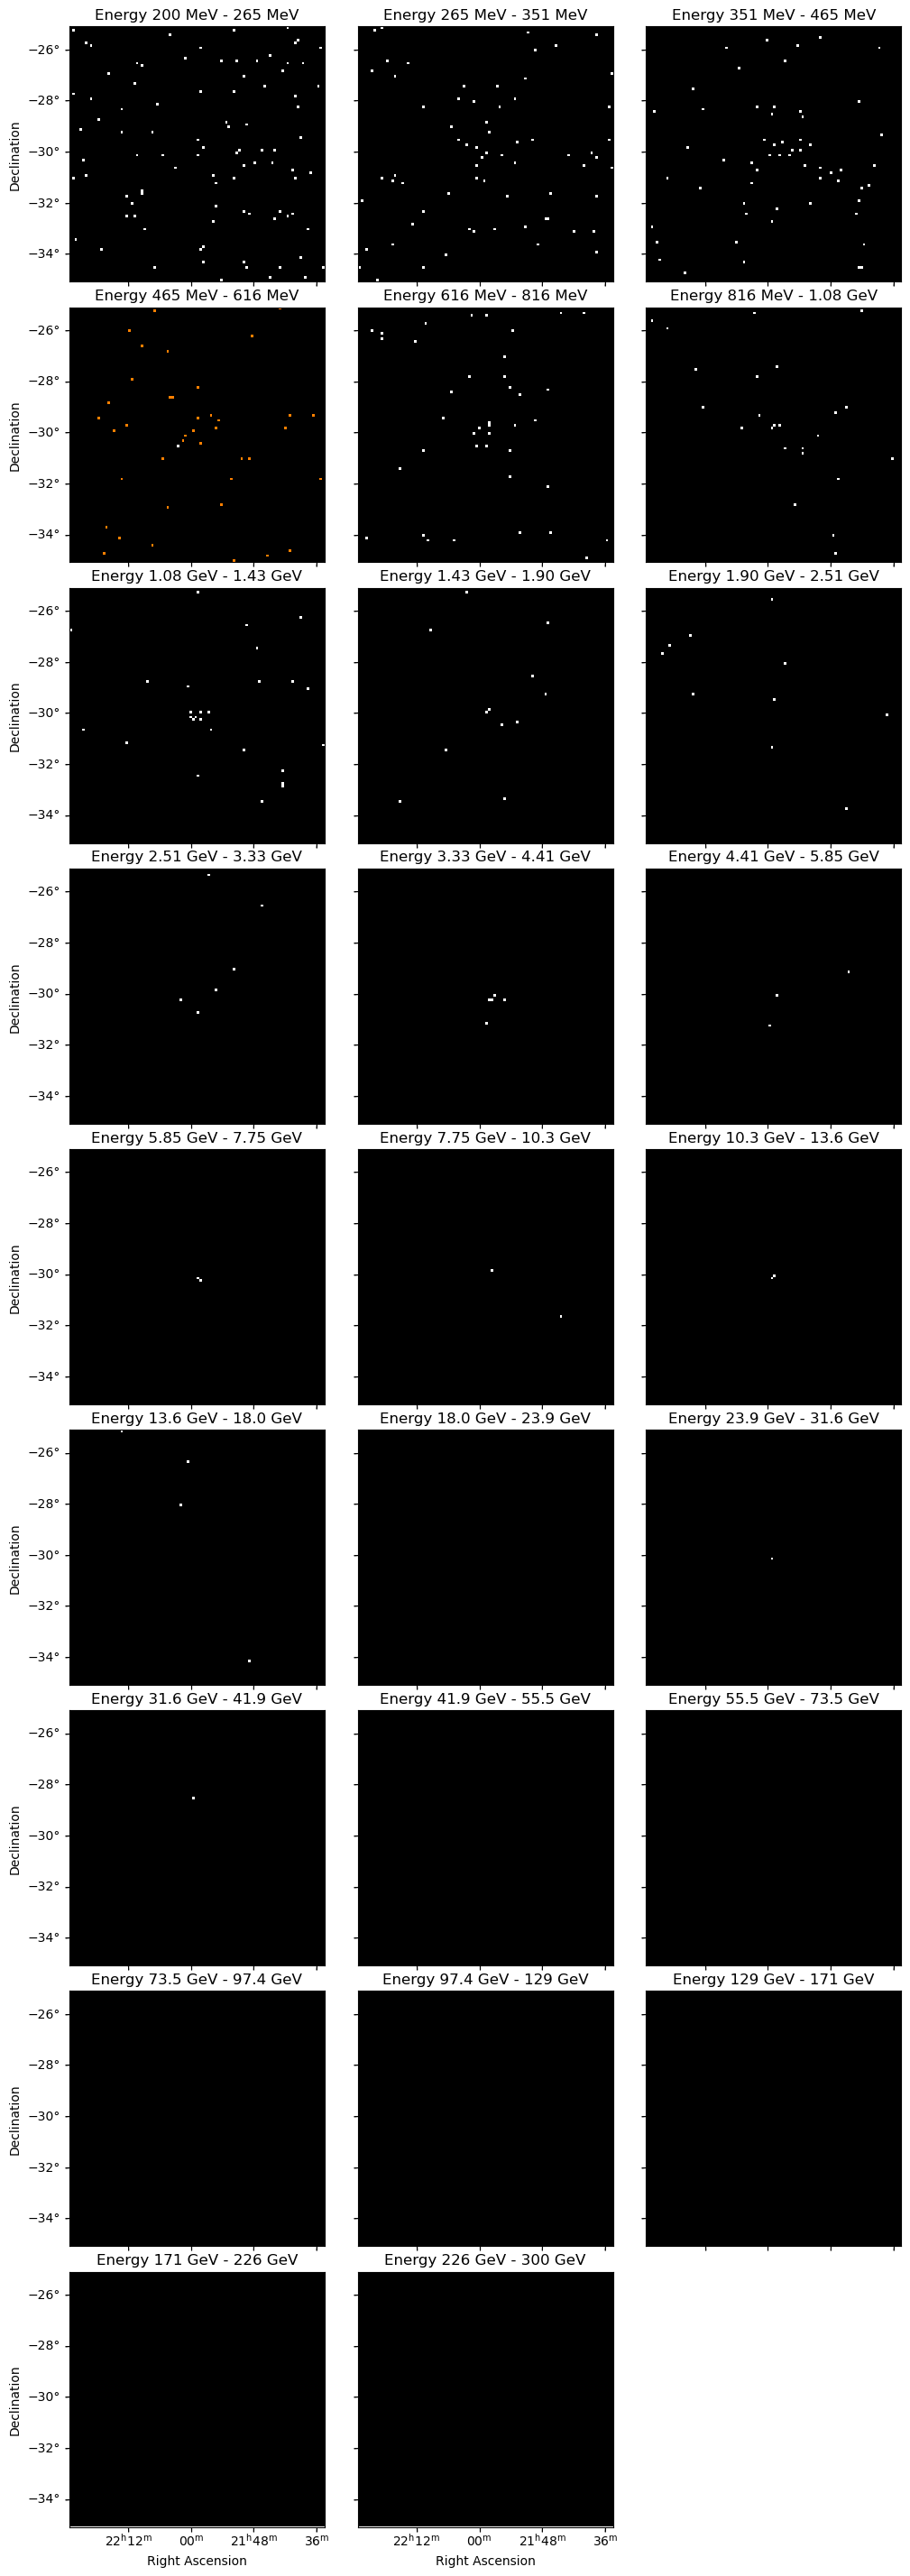

In [22]:
counts.plot_grid();

Read the exposure using a `Map.read`. The exposure is stored in 'bexpmap_roi_00.fits'.

In [23]:
exposure = Map.read("bexpmap_roi_00.fits")

the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]
Set MJD-OBS to 54704.000000 from DATE-OBS.
Set MJD-END to 54715.000000 from DATE-END'. [astropy.wcs.wcs]


In [24]:
print(exposure)

WcsNDMap

	geom  : WcsGeom 
 	axes  : ['lon', 'lat', 'energy_true']
	shape : (np.int64(100), np.int64(100), 14)
	ndim  : 3
	unit  : cm2 s
	dtype : >f4



In [25]:
energy_true = exposure.geom.axes["energy_true"]

In [26]:
irf_geom = WcsGeom(wcs=counts.geom.wcs, npix=counts.geom.npix, axes=[energy_true])

In [27]:
exposure = exposure.interp_to_geom(irf_geom)
print(exposure)

WcsNDMap

	geom  : WcsGeom 
 	axes  : ['lon', 'lat', 'energy_true']
	shape : (np.int64(100), np.int64(100), 14)
	ndim  : 3
	unit  : cm2 s
	dtype : float64



<WCSAxes: >

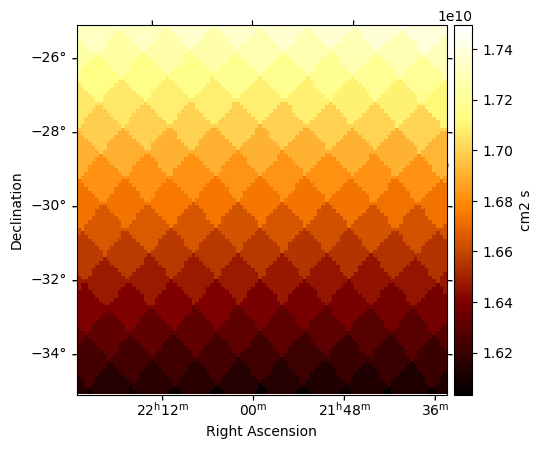

In [28]:
exposure.sum_over_axes().plot(add_cbar=True)

Read the psf using `PSFMap.read`. The psf is stored in 'psf_00.fits'.

In [29]:
psf = PSFMap.read('psf_00.fits', format='gtpsf')
print(psf)

RegionNDMap

	geom  : RegionGeom 
 	axes  : ['lon', 'lat', 'rad', 'energy_true']
	shape : (1, 1, 200, 26)
	ndim  : 4
	unit  : 1 / sr
	dtype : >f8



<WCSAxes: >

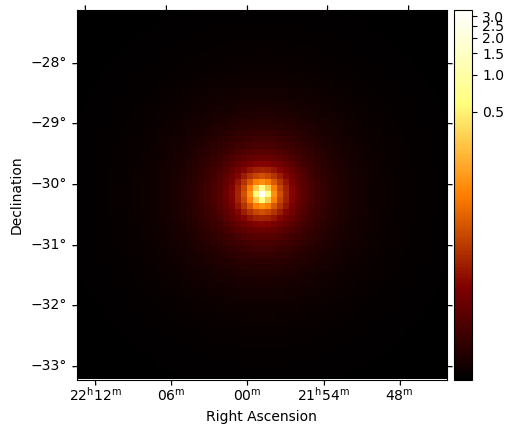

In [30]:
psf_kernel = psf.get_psf_kernel(
    position=irf_geom.center_skydir,
    geom=irf_geom,
    max_radius="3 deg"
)
psf_kernel.psf_kernel_map.sum_over_axes().plot(stretch='log', add_cbar=True)

Create a diagonal energy dispersion matrix using `EDispKernelMap.from_diagonal_response` and the energy axes of the counts map

<Axes: xlabel='True Energy [$\\mathrm{MeV}$]', ylabel='Energy [$\\mathrm{GeV}$]'>

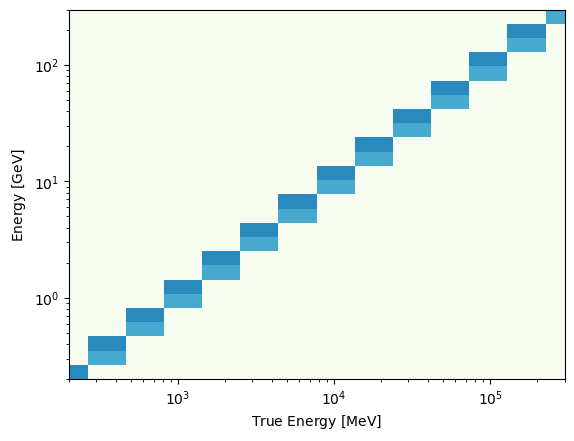

In [31]:
edisp = EDispKernelMap.from_diagonal_response(
    energy_axis=counts.geom.axes["energy"],
    energy_axis_true=exposure.geom.axes["energy_true"],
)
edisp.get_edisp_kernel().plot_matrix()

Create the fermi dataset by putting the counts and IRFs that we have created above into a `MapDataset`.

In [32]:
fermi_dataset = MapDataset(
    counts=counts,
    exposure=exposure,
    edisp=edisp,
    psf=psf,
    name="fermi-lat"
)

In [33]:
fermi_dataset

## Perform joint fit
Now that we have our two dataset, we can try to fit them together.

First, we need to put them together in a `Datasets` object.

In [34]:
datasets = Datasets([hess_dataset, fermi_dataset])

In [35]:
datasets

Then we also need two background model specific to Fermi:

In [36]:
diffuse_iso = create_fermi_isotropic_diffuse_model(
    filename='iso_P8R3_SOURCE_V3_v1.txt'
)
diffuse_iso.datasets_names = fermi_dataset.name
print(diffuse_iso)

SkyModel

  Name                      : fermi-diffuse-iso
  Datasets names            : fermi-lat
  Spectral model type       : CompoundSpectralModel
  Spatial  model type       : ConstantSpatialModel
  Temporal model type       : 
  Parameters:
    tilt                  (frozen):      0.000                   
    norm                          :      1.000   +/-    0.00             
    reference             (frozen):      1.000       TeV         
    value                 (frozen):      1.000       1 / sr      




In [37]:
template_diffuse = TemplateSpatialModel.read(
    filename="gll_iem_v07.fits",
    normalize=False
)
diffuse_iem = SkyModel(
    spectral_model=PowerLawNormSpectralModel(),
    spatial_model=template_diffuse,
    name='diffuse-iem'
)

diffuse_iem.datasets_names = fermi_dataset.name

And the other sources in the region of interest. For this, first read the 4FGL Fermi catalog via `CATALOG_REGISTRY`


In [38]:
catalog_4fgl = CATALOG_REGISTRY.get_cls("4fgl")()  

Select only the sources inside the dataset spatial geometry:

In [39]:
in_geom = geom.to_image().contains(catalog_4fgl.positions)
catalog_4fgl_gc = catalog_4fgl[in_geom]
models_4fgl_gc = catalog_4fgl_gc.to_models()


But these are too many to fit all together. Freeze all parameters of all sources except for bright and closeby sources (this will need to be optimized for your different analysis cases in real applications)

In [40]:
separations  = catalog_4fgl_gc.positions.separation(target_pos).deg
significance = catalog_4fgl_gc.table['Signif_Avg']

for k,s in enumerate(models_4fgl_gc):
    #set norm and spectral par free for close sources and very bright ones:
    if separations[k]<5 and significance[k]>30:
        free_pars = ['norm','amplitude','alpha','index','index_1','index_2','beta','lambda_']
    #set norm free for close, but not bright sources
    elif separations[k]<5:
        free_pars = ['norm','amplitude']
    #do not free anything for all other sources
    else:
        free_pars = []
    #Apply the freeze/non-freeze settings
    for j,p in enumerate(models_4fgl_gc[k].parameters):
        if p.name in free_pars:
            p.frozen = False
        else:
            p.frozen = True
    

## Make the final model

Combine all Fermi relevant models

In [41]:
model_list = Models(list(models_4fgl_gc)+[diffuse_iem]+[diffuse_iso])

Our source of interest is registered under its 4FGL name

In [42]:
source_name_4fgl = "4FGL J2158.8-3013"

Assign the models to our datasets

In [43]:
fermi_dataset.models = model_list
hess_dataset.models = [models_4fgl_gc[source_name_4fgl]]

## Fitting the data:

Try to fit the data using an `ExpCutoffPowerLawSpectralModel` including EBL absorption for our source model

In [44]:
spectral_model = ExpCutoffPowerLawSpectralModel(
    index=2.0,
    amplitude=1e-12 * u.Unit("cm-2 s-1 TeV-1"),
    reference=1 * u.TeV,
    lambda_=0.1 / u.TeV,
    alpha=1,
)

In [45]:
abs_model = EBLAbsorptionNormSpectralModel.read_builtin()
abs_model.redshift.value = 0.116


In [46]:
spectral_model_abs = spectral_model * abs_model
datasets.models[source_name_4fgl].spectral_model = spectral_model_abs

In [47]:
fit_joint = Fit()
result_joint = fit_joint.run(datasets=datasets)

In [48]:
result_joint

In [49]:
spectral_model

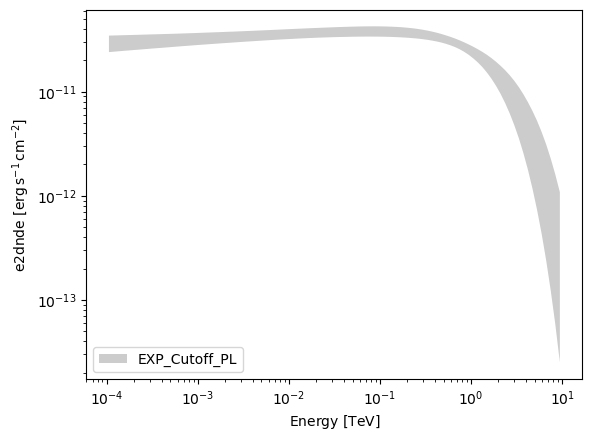

In [50]:
spectral_model.plot_error(
    energy_bounds=[0.1 * u.GeV, 10 * u.TeV],
    sed_type="e2dnde",
    label="EXP_Cutoff_PL",
)
plt.legend()

Produce the flux-points

In [51]:
fp_hess = FluxPointsEstimator(
    energy_edges=hess_dataset.counts.geom.axes["energy"].edges[::2], 
    source=source_name_4fgl, 
    selection_optional="all"
).run(datasets=hess_dataset)

In [52]:
#Merging every 2 energy bins to save time for the demo here
fp_fermi = FluxPointsEstimator(
    energy_edges=fermi_dataset.counts.geom.axes["energy"].edges[::4], 
    source=source_name_4fgl, 
    selection_optional="all"
).run(datasets=fermi_dataset)

In [53]:
fp_hess_intr = fp_hess.copy(reference_model=SkyModel(spectral_model=spectral_model))
fp_fermi_intr = fp_fermi.copy(reference_model=SkyModel(spectral_model=spectral_model))

Changing the reference model will change the fluxes. Handle with care.
Changing the reference model will change the fluxes. Handle with care.


/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(


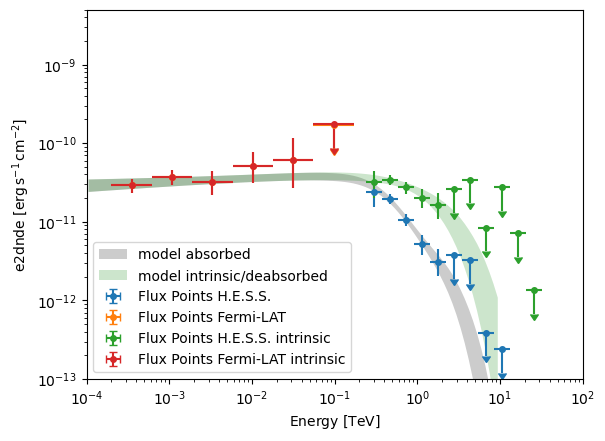

In [54]:
spectral_model_abs.plot_error(
    energy_bounds=[0.1 * u.GeV, 10 * u.TeV],
    sed_type="e2dnde",
    label="model absorbed",
)
spectral_model.plot_error(
    energy_bounds=[0.1 * u.GeV, 10 * u.TeV],
    sed_type="e2dnde",facecolor="green",
    label="model intrinsic/deabsorbed",
)
# Add the flux points of H.E.S.S. and Fermi-LAT
fp_hess.plot(sed_type="e2dnde", label="Flux Points H.E.S.S.")
fp_fermi.plot(sed_type="e2dnde", label="Flux Points Fermi-LAT")

fp_hess_intr.plot(sed_type="e2dnde", label="Flux Points H.E.S.S. intrinsic")
fp_fermi_intr.plot(sed_type="e2dnde", label="Flux Points Fermi-LAT intrinsic")

plt.ylim(1e-13, 5e-9)
plt.xlim(1e-4, 100)
plt.legend()


## Open problem:
Fit a physical model instead of Exp Cuoff PL. E.g. Inverse Compton using the Naima Plugin inside Gammapy (careful, for real cases beaming needs to be taken into account for blazars and externals plugings such as jetset or agnpy are more recommendable)

### 1. Define the physical model
In blazars, the high-energy peak is usually explained by synchrotron self-Compton (SSC) emission: the electrons in the jet emit synchrotron photons in the magnetic field, and the same electrons up-scatter these photons to gamma-ray energies (Inverse Compton).

We model this with Naima: an exponential cutoff power-law electron spectrum inside a spherical region with magnetic field `B` and radius `radius`. `NaimaSpectralModel` computes the synchrotron photon density inside the region and uses it as seed photons for the Inverse Compton emission.

This is a simplified model: it ignores the Doppler boosting of the jet, so the fitted parameters are not physical. For real blazar modelling use dedicated packages such as agnpy or jetset.

In [55]:
import naima
from astropy.cosmology import Planck18
from gammapy.modeling.models import NaimaSpectralModel

# Energy distribution of the electrons
electrons = naima.models.ExponentialCutoffPowerLaw(
    amplitude=5e35 / u.eV,
    e_0=1 * u.TeV,
    alpha=2.5,
    e_cutoff=5 * u.TeV,
)

# Inverse Compton scattering of these electrons
ic = naima.models.InverseCompton(electrons, Eemin=1 * u.GeV)

# Use the synchrotron photons of the same electrons as seed photons (SSC).
# The flux depends on the distance to the source (z = 0.116)
naima_model = NaimaSpectralModel(
    ic,
    distance=Planck18.luminosity_distance(0.116),
    seed="SSC",
    nested_models={"SSC": {"B": 0.1 * u.G, "radius": 1e16 * u.cm}},
)

# e_0 is only a reference energy and beta the cutoff shape: keep them fixed.
# Without X-ray/optical data the synchrotron peak is unknown, so B and radius cannot be fitted either.
naima_model.e_0.frozen = True
naima_model.beta.frozen = True
naima_model.B.frozen = True
naima_model

### 2. Joint fit of the H.E.S.S. and Fermi-LAT data
As for the exponential cutoff power law, we replace the spectral model of our source, this time by the SSC model times the EBL absorption. The source model is shared by both datasets, so the fit uses the H.E.S.S. ON/OFF counts and the Fermi-LAT counts map at the same time.

The SSC model is much slower to evaluate than an analytic model, so we keep all other models fixed and only fit our source. This still takes several minutes.

In [56]:
ic_model = naima_model * abs_model

datasets.models[source_name_4fgl].spectral_model = ic_model

#Needed because otherwise Gammapy does not update the number of parameters needed in the model and the fit will fail
for dataset in datasets:
    dataset.models=dataset.models


In [57]:

fit_ic = Fit()
result_ic = fit_ic.run(datasets=datasets)
print(result_ic)

OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully, but uncertainties are unreliable.
	nfev       : 773
	total stat : 4979.88

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.



In [58]:
naima_model.parameters.to_table()

type,name,value,unit,error,min,max,frozen,link,prior
str1,str9,float64,str4,float64,float64,float64,bool,str1,str1
,amplitude,4.8085e+35,eV-1,2.831e+35,nan,nan,False,,
,e_0,1.0000e+00,TeV,0.000e+00,nan,nan,True,,
,alpha,2.4923e+00,,4.007e-02,nan,nan,False,,
,e_cutoff,5.4812e+00,TeV,2.968e+00,nan,nan,False,,
,beta,1.0000e+00,,0.000e+00,nan,nan,True,,
,B,1.0000e-01,G,0.000e+00,nan,nan,True,,
,radius,1.0000e+16,cm,0.000e+00,nan,nan,True,,


### 3. Plot the result
Compare the intrinsic model (as emitted by the source) with the absorbed one (as seen on Earth).

/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/gammapy/modeling/models/spectral.py:650: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)
/home/heckmann/miniforge3/envs/cads-2026/lib/python3.12/site-packages/gammapy/maps/region/ndmap.py:154: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(


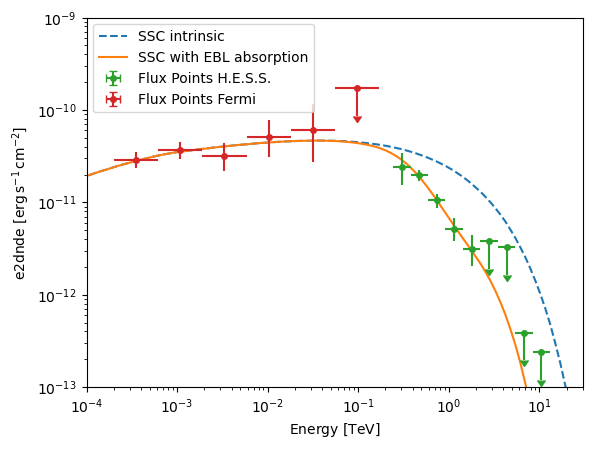

In [59]:
energy_bounds = [0.1 * u.GeV, 30 * u.TeV]

ax = naima_model.plot(
    energy_bounds=energy_bounds, sed_type="e2dnde", ls="--", label="SSC intrinsic"
)
ic_model.plot(
    energy_bounds=energy_bounds, sed_type="e2dnde", ax=ax, label="SSC with EBL absorption"
)
fp_hess.plot(ax=ax, sed_type="e2dnde", label="Flux Points H.E.S.S.")
fp_fermi.plot(ax=ax, sed_type="e2dnde", label="Flux Points Fermi")

# FluxPoints.plot() resets the x-axis to its own energy range, so set the limits at the end
ax.set_xlim(1e-4, 30)  # TeV
ax.set_ylim(1e-13, 1e-9)
plt.legend()